In [19]:
import pandas as pd
import matplotlib.pyplot as plt
print("Working")

Working


In [20]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("../test data/erg/concept2-result-115770245.csv")
df = df.rename(columns={
    "Time (seconds)": "t", "Distance (meters)": "dist",
    "Pace (seconds)": "pace500", "Watts": "power",
    "Cal/Hr": "cal_hr", "Stroke Rate": "spm", "Heart Rate": "hr",
}).drop(columns=["Number", "hr"])
df = df.sort_values("t").reset_index(drop=True)

In [21]:
df["power_from_pace"] = 2.80 / (df["pace500"] / 500)**3
print((df["power"] - df["power_from_pace"]).abs().describe())

count    2.490000e+02
mean     2.475067e-01
std      1.254992e-01
min      1.136868e-13
25%      1.487255e-01
50%      2.598672e-01
75%      3.200530e-01
max      4.829289e-01
dtype: float64


In [22]:
df["work_J"] = np.concatenate([[0], np.cumsum(
    0.5 * (df["power"].values[1:] + df["power"].values[:-1]) * np.diff(df["t"].values))])

Mean power 318.9 W | SD 4.4 W | work 88.8 kJ


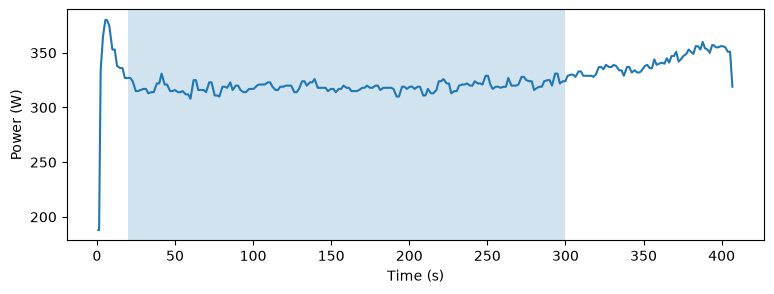

In [23]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(df["t"], df["power"]); ax.set_xlabel("Time (s)"); ax.set_ylabel("Power (W)")

t_start, t_end = 20, 300      # adjust after looking at the plot
ss = df[(df["t"] >= t_start) & (df["t"] <= t_end)]
ax.axvspan(t_start, t_end, alpha=0.2)

P_mean = ss["power"].mean()
W_ss = np.sum(0.5 * (ss["power"].values[1:] + ss["power"].values[:-1]) * np.diff(ss["t"].values))
print(f"Mean power {P_mean:.1f} W | SD {ss['power'].std():.1f} W | work {W_ss/1000:.1f} kJ")

In [24]:
print(f"Total work: {df['work_J'].iloc[-1]/1000:.1f} kJ over {df['t'].iloc[-1]:.0f} s")

Total work: 132.3 kJ over 407 s


In [25]:
valid = df["spm"].notna() & (df["t"] > 10)
df.loc[valid, "work_per_stroke_J"] = df.loc[valid, "power"] * 60 / df.loc[valid, "spm"]

In [26]:
eta = 0.25   # assumed: metabolic work = 4 x mechanical work

df["kcal_per_stroke"] = df["work_per_stroke_J"] / (eta * 4184)
df["kcal_per_min"] = df["kcal_per_stroke"] * df["spm"]

In [ ]:
def kcal_per_stroke(watts, spm, eta=0.25):
    T = 60.0 / spm              # stroke period, s
    e_mech = watts * T          # J
    e_met = e_mech / eta        # J
    return e_met / 4184.0       # kcal

ok = valid  # strokes with a stroke rate, after the first 10 s (same as work_per_stroke_J)
session_kcal = sum(kcal_per_stroke(w, s) for w, s in zip(df.loc[ok, "power"], df.loc[ok, "spm"]))
print(f"Session: {session_kcal:.1f} kcal over {ok.sum()} strokes")